# Cell 1 — Import Required Libraries

In [1]:
# Import utilities for file management and warning control.
import os
import glob
import zipfile
import warnings

# Import libraries for data analysis and visualization.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for data splitting and model tuning.
from sklearn.model_selection import train_test_split, GridSearchCV

# Import preprocessing tools.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import regression algorithms.
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Import regression evaluation metrics.
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configure consistent plots and reproducible experiments.
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


# Cell 2 — Mount Google Drive

In [2]:
# Import the Google Drive integration for Google Colab.
from google.colab import drive

# Mount Google Drive to access the uploaded dataset.
drive.mount('/content/drive')

# Define the folder where all project results will be saved.
OUTPUT_DIR = "/content/drive/MyDrive/Housing_Regression_Results"

# Create the output folder if it does not already exist.
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder:", OUTPUT_DIR)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/Housing_Regression_Results


# Cell 3 — Find and load the dataset

In [3]:
# Search Google Drive for the uploaded housing.csv file.
csv_files = glob.glob(
    "/content/drive/MyDrive/**/housing.csv",
    recursive=True
)

# Stop if the file cannot be found.
if not csv_files:
    raise FileNotFoundError(
        "housing.csv was not found. Update DATA_PATH to your actual file path."
    )

# Select the first matching dataset path.
DATA_PATH = csv_files[0]

# Load the dataset into a pandas DataFrame.
df = pd.read_csv(DATA_PATH)

# Display the file path, dataset dimensions, and first five records.
print("Dataset path:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset path: /content/drive/MyDrive/housing.csv
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# Cell 4 — Explore the dataset

In [4]:
# Display all column names.
print("Columns:")
print(df.columns.tolist())

# Display data types and non-null counts.
print("\nDataset information:")
df.info()

# Count missing values in each column.
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))

# Count duplicate rows.
print("\nDuplicate rows:", df.duplicated().sum())

# Display descriptive statistics for numeric and categorical columns.
display(df.describe(include="all").T)

Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values:


,Missing Count
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0



Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Cell 5 — Clean columns and identify the target

In [5]:
# Normalize column names by converting them to lowercase and removing spaces.
df.columns = df.columns.str.strip().str.lower()

# Remove duplicate rows from the dataset.
df = df.drop_duplicates().copy()

# Identify common target-column names used by housing datasets.
possible_targets = [
    "median_house_value",
    "medhouseval",
    "median_house_value_usd",
    "price",
    "saleprice"
]

# Find the first recognized target column.
TARGET = next(
    (col for col in possible_targets if col in df.columns),
    None
)

# Stop if no known target is found rather than silently training the wrong model.
if TARGET is None:
    raise ValueError(
        "No recognized target column was found. "
        f"Available columns: {df.columns.tolist()}. "
        "Set TARGET manually after checking the dataset."
    )

# Convert the target to numeric values and remove rows with invalid targets.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()

print("Selected target:", TARGET)
print("Cleaned dataset shape:", df.shape)
display(df.head())

Selected target: median_house_value
Cleaned dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# Cell 6 — Analyze target distribution

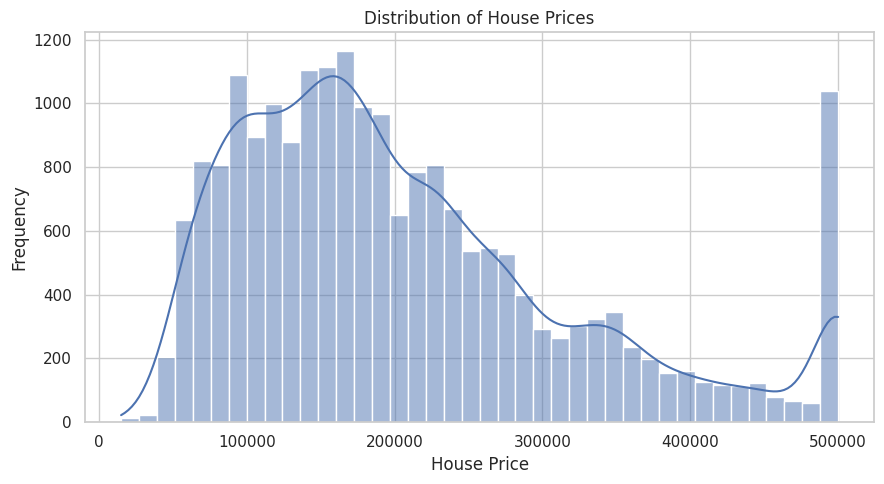

In [6]:
# Plot the distribution of the target house-price variable.
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x=TARGET, bins=40, kde=True)

# Add descriptive labels and a title.
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.tight_layout()

# Save the visualization to Google Drive.
plt.savefig(f"{OUTPUT_DIR}/01_target_distribution.png", dpi=300)

# Display the plot.
plt.show()

# Cell 7 — Correlation heatmap

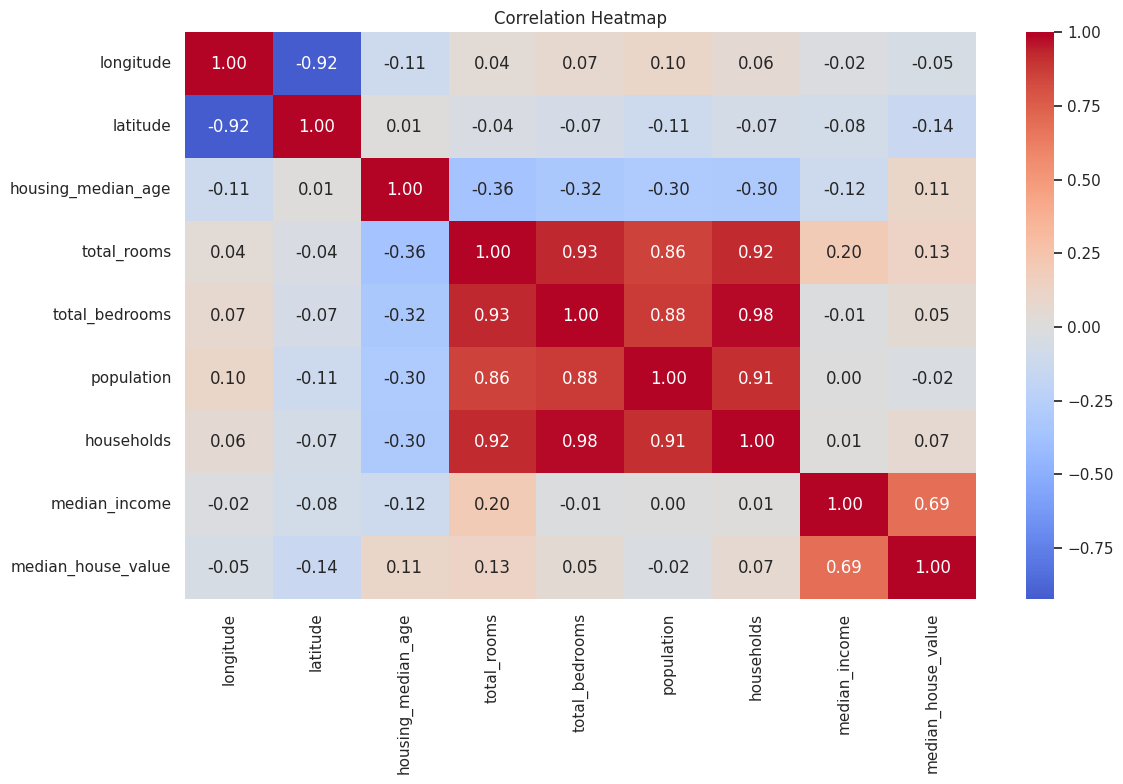

,Correlation with Target
median_income,0.688075
latitude,-0.144160
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
longitude,-0.045967
population,-0.024650


In [7]:
# Select numeric columns for correlation analysis.
numeric_df = df.select_dtypes(include=np.number)

# Calculate pairwise correlations among numeric features.
correlation = numeric_df.corr()

# Draw the correlation heatmap.
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

# Add a title and improve layout.
plt.title("Correlation Heatmap")
plt.tight_layout()

# Save the heatmap to Google Drive.
plt.savefig(f"{OUTPUT_DIR}/02_correlation_heatmap.png", dpi=300)

# Display the heatmap.
plt.show()

# Show each numeric feature's correlation with the target.
if TARGET in correlation.columns:
    target_corr = correlation[TARGET].drop(TARGET)
    target_corr = target_corr.reindex(
        target_corr.abs().sort_values(ascending=False).index
    )
    display(target_corr.to_frame("Correlation with Target"))

# Cell 8 — Feature engineering

In [8]:
# Create useful ratio features when their source columns are available.
if {"total_rooms", "households"}.issubset(df.columns):
    # Calculate the average number of rooms per household.
    df["rooms_per_household"] = (
        df["total_rooms"] / df["households"].replace(0, np.nan)
    )

if {"total_bedrooms", "total_rooms"}.issubset(df.columns):
    # Calculate the proportion of bedrooms among total rooms.
    df["bedrooms_per_room"] = (
        df["total_bedrooms"] / df["total_rooms"].replace(0, np.nan)
    )

if {"population", "households"}.issubset(df.columns):
    # Calculate the average population per household.
    df["population_per_household"] = (
        df["population"] / df["households"].replace(0, np.nan)
    )

# Create an interaction feature when both required columns exist.
if {"median_income", "housing_median_age"}.issubset(df.columns):
    # Represent the combined effect of income and housing age.
    df["income_x_house_age"] = (
        df["median_income"] * df["housing_median_age"]
    )

# Replace infinite values created by division with missing values.
df = df.replace([np.inf, -np.inf], np.nan)

# Display the updated features.
print("Feature engineering completed.")
print(df.columns.tolist())
display(df.head())


Feature engineering completed.
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_house_age']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_house_age
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,341.3332
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,174.3294
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,377.3848
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,293.4412
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,200.0024


# Cell 9 — Separate features and target

In [9]:
# Separate the input features from the target variable.
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Detect numeric features automatically.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Detect categorical features automatically.
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Display the detected feature types.
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Split the data into training and testing subsets.
# The test set remains unseen during preprocessing and model tuning.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Display the sizes of both subsets.
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_house_age']
Categorical features: ['ocean_proximity']
Training samples: 16512
Testing samples: 4128


# Cell 10 — Build the preprocessing pipeline

In [10]:
# Fill missing numeric values with the median and standardize numeric features.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fill missing categorical values and encode categories as binary features.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing steps to each feature type.
# All transformations are fitted within the training pipeline to prevent leakage.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# Cell 11 — Train OLS (Ordinary Least Squares)

In [11]:
# Create a pipeline combining preprocessing and ordinary linear regression.
ols_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Fit the OLS model using the training data.
ols_model.fit(X_train, y_train)

# Predict house prices for the unseen test data.
ols_predictions = ols_model.predict(X_test)

# Confirm that training and prediction completed.
print("OLS model trained successfully.")
print("First five predictions:", ols_predictions[:5])

OLS model trained successfully.
First five predictions: [ 37218.26384014 139754.90357    295755.21092525 280255.75113142
 264184.72967773]


# Cell 12 — Ridge Regression with GridSearchCV

In [12]:
# Create a Ridge regression pipeline with L2 regularization.
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Define alpha values to test during cross-validation.
ridge_param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Search for the alpha value with the lowest cross-validation RMSE.
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train and tune Ridge using only the training set.
ridge_search.fit(X_train, y_train)

# Retrieve the best Ridge pipeline and predict on the test set.
best_ridge = ridge_search.best_estimator_
ridge_predictions = best_ridge.predict(X_test)

# Display the best hyperparameter and cross-validation performance.
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Ridge parameters: {'regressor__alpha': 1}
Best Ridge CV RMSE: 67720.72484368543


# Cell 13 — Lasso Regression with GridSearchCV

In [13]:
# Create a Lasso regression pipeline with L1 regularization.
lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

# Define alpha values for the Lasso hyperparameter search.
lasso_param_grid = {
    "regressor__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Use five-fold cross-validation to find the best alpha.
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Fit and tune the Lasso pipeline on the training data.
lasso_search.fit(X_train, y_train)

# Retrieve the best Lasso model and predict on the test set.
best_lasso = lasso_search.best_estimator_
lasso_predictions = best_lasso.predict(X_test)

# Display the best hyperparameter and cross-validation RMSE.
print("Best Lasso parameters:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Lasso parameters: {'regressor__alpha': 1}
Best Lasso CV RMSE: 67721.65288914007


# Cell 14 — Evaluate all regression models

In [14]:
# Define a function that calculates the required regression metrics.
def calculate_metrics(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

# Calculate metrics using the same held-out test set for each model.
results = pd.DataFrame([
    calculate_metrics("OLS", y_test, ols_predictions),
    calculate_metrics("Ridge", y_test, ridge_predictions),
    calculate_metrics("Lasso", y_test, lasso_predictions)
])

# Rank the models by test RMSE, with lower values ranked first.
results = results.sort_values("RMSE").reset_index(drop=True)

# Display the comparison table.
print("Regression model evaluation:")
display(results.round(4))

# Save the comparison table to Google Drive.
results.to_csv(
    f"{OUTPUT_DIR}/model_comparison.csv",
    index=False
)

Regression model evaluation:


,Model,RMSE,MAE,R2
0,OLS,69048.1923,49376.4886,0.6362
1,Lasso,69049.2483,49377.3433,0.6362
2,Ridge,69056.2204,49382.6281,0.6361


# Cell 15 — Compare model errors visually

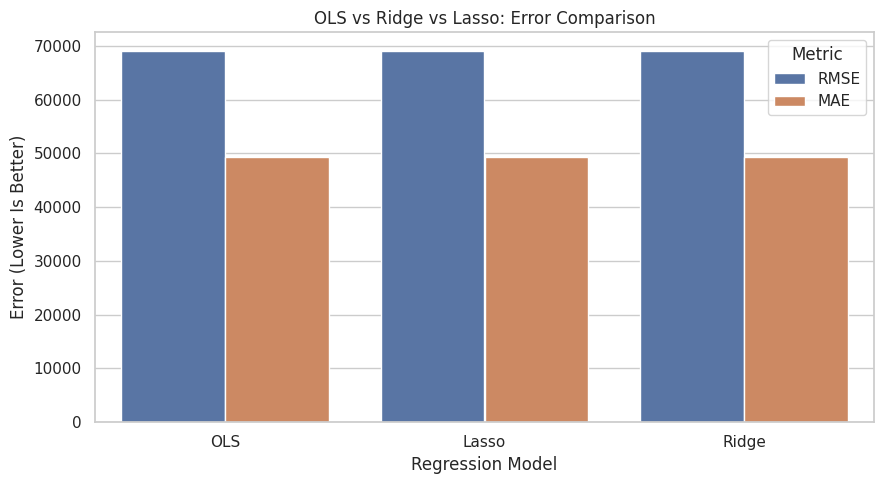

In [15]:
# Reshape the RMSE and MAE columns to make grouped plotting easier.
error_data = results.melt(
    id_vars="Model",
    value_vars=["RMSE", "MAE"],
    var_name="Metric",
    value_name="Error"
)

# Plot the error metrics for all three models.
plt.figure(figsize=(9, 5))
sns.barplot(data=error_data, x="Model", y="Error", hue="Metric")

# Add plot labels and save the figure.
plt.title("OLS vs Ridge vs Lasso: Error Comparison")
plt.xlabel("Regression Model")
plt.ylabel("Error (Lower Is Better)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_error_comparison.png", dpi=300)

# Display the error comparison.
plt.show()

# Cell 16 — Compare R² scores

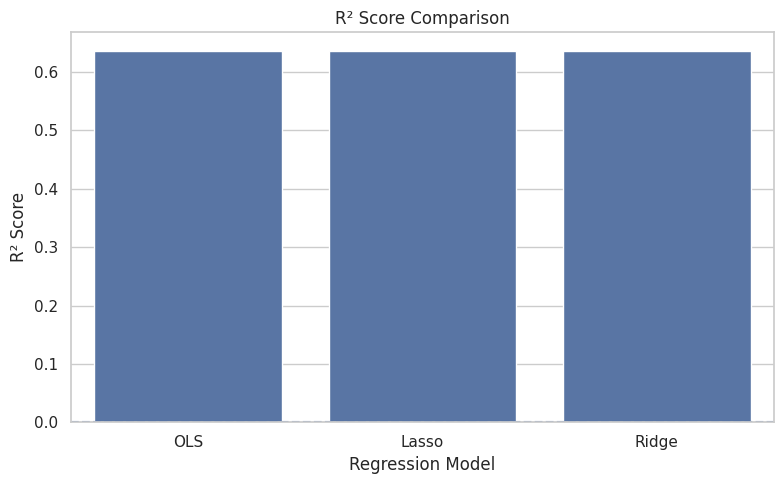

In [16]:
# Visualize the R-squared score for each regression model.
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="Model", y="R2")

# Add a reference line at zero to help interpret negative R-squared scores.
plt.axhline(0, linestyle="--")

# Add labels and save the plot.
plt.title("R² Score Comparison")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_r2_comparison.png", dpi=300)

# Display the R-squared comparison.
plt.show()

# Cell 17 — Actual vs Predicted plots

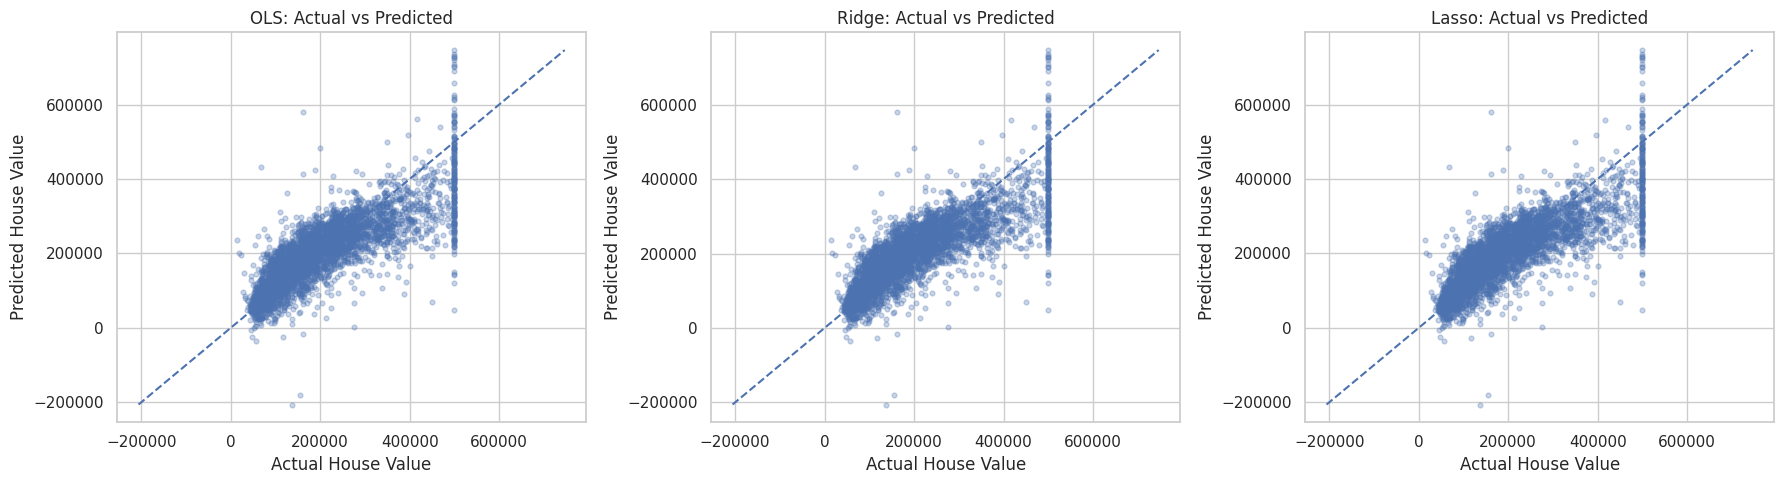

In [17]:
# Store the test predictions from each fitted regression model.
predictions = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

# Create one subplot for each model.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Compare actual and predicted house values for each model.
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    # Plot actual values against predicted values.
    ax.scatter(y_test, y_pred, alpha=0.3, s=12)

    # Draw the ideal reference line where predictions equal actual values.
    lower = min(y_test.min(), np.min(y_pred))
    upper = max(y_test.max(), np.max(y_pred))
    ax.plot([lower, upper], [lower, upper], linestyle="--")

    # Label the subplot.
    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

# Adjust spacing, save the figure, and display it.
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_actual_vs_predicted.png", dpi=300)
plt.show()

# Cell 18 — Residual error plots

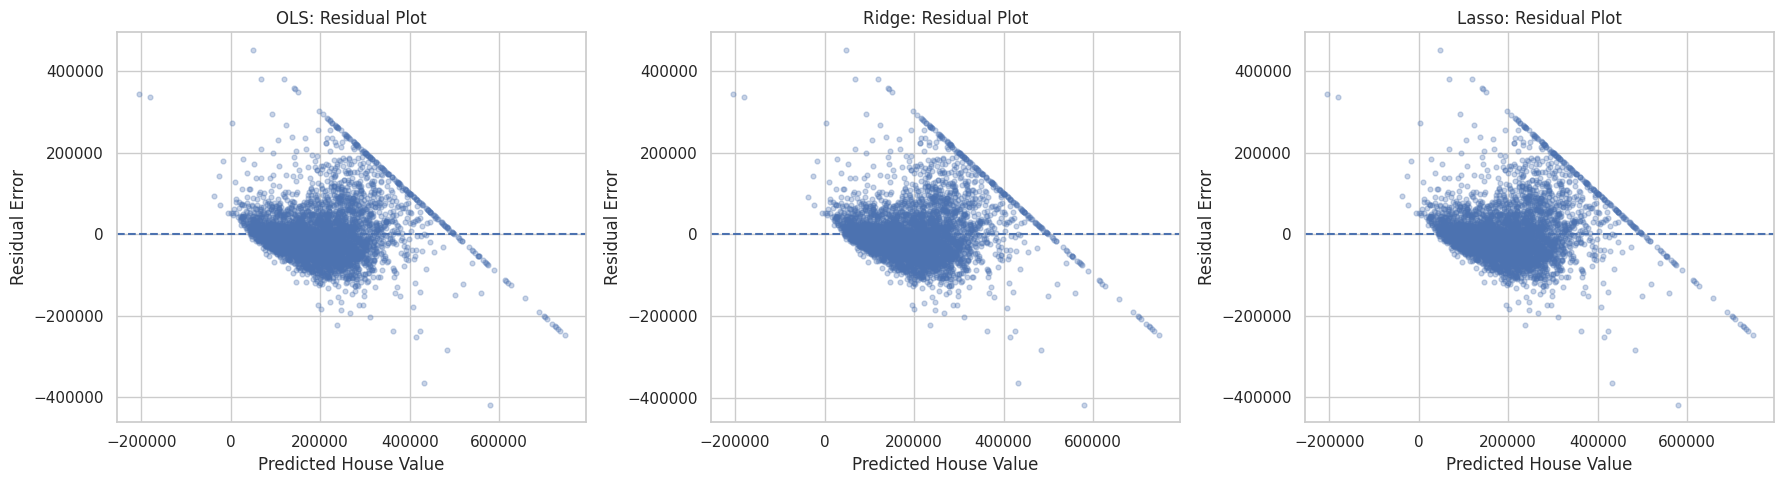

In [18]:
# Create subplots to examine residual errors for all three models.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Calculate residuals and plot them against predicted values.
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    # Residual = actual value minus predicted value.
    residuals = np.asarray(y_test) - np.asarray(y_pred)

    # Plot the residuals and draw the zero-error reference line.
    ax.scatter(y_pred, residuals, alpha=0.3, s=12)
    ax.axhline(0, linestyle="--")

    # Label the subplot.
    ax.set_title(f"{model_name}: Residual Plot")
    ax.set_xlabel("Predicted House Value")
    ax.set_ylabel("Residual Error")

# Save and display the residual plots.
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_residual_plots.png", dpi=300)
plt.show()

# Cell 19 — Residual distribution curves

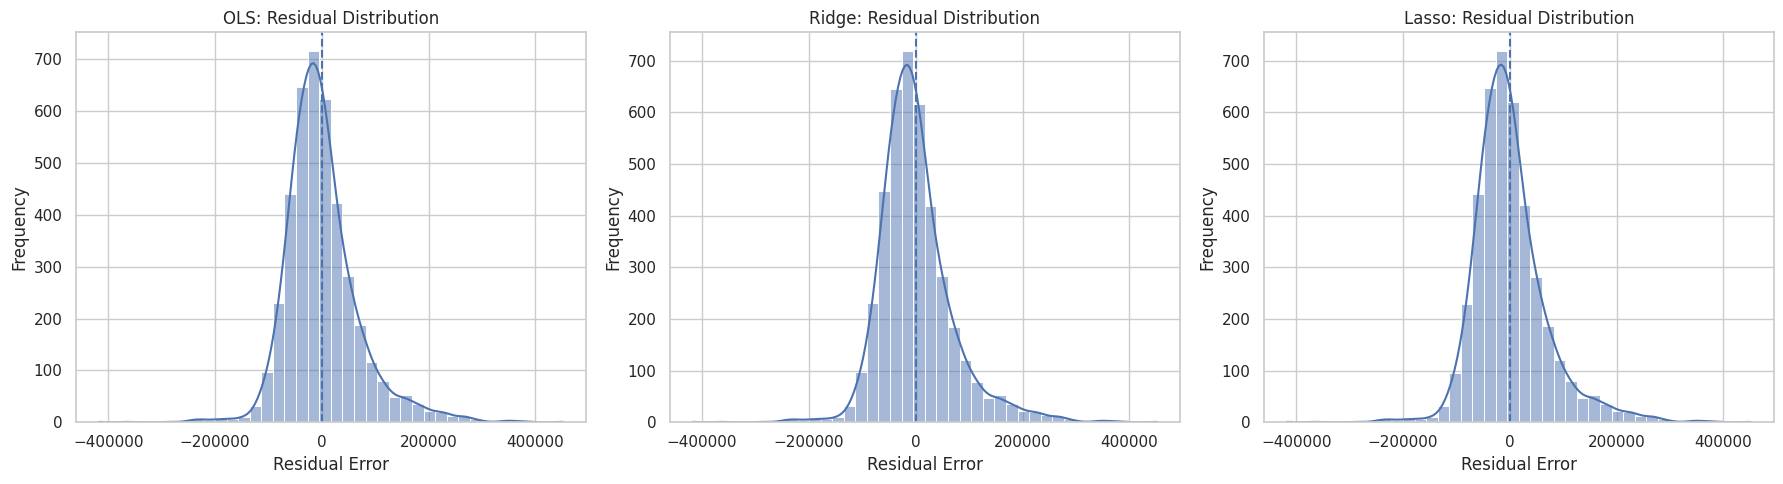

In [19]:
# Create a separate residual distribution plot for each model.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Calculate and visualize each model's residual distribution.
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    # Compute prediction errors on the test set.
    residuals = np.asarray(y_test) - np.asarray(y_pred)

    # Plot the residual histogram and its kernel density estimate.
    sns.histplot(residuals, kde=True, bins=40, ax=ax)
    ax.axvline(0, linestyle="--")

    # Label the subplot.
    ax.set_title(f"{model_name}: Residual Distribution")
    ax.set_xlabel("Residual Error")
    ax.set_ylabel("Frequency")

# Save and display the distribution plots.
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_residual_distributions.png", dpi=300)
plt.show()

# Cell 20 — Multicollinearity analysis using VIF

In [20]:
# Import the Variance Inflation Factor calculation function.
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numeric features from the training set only.
X_numeric_train = X_train[numeric_features].copy()

# Impute missing numeric values using medians learned from the training data.
vif_imputer = SimpleImputer(strategy="median")
X_numeric_train = pd.DataFrame(
    vif_imputer.fit_transform(X_numeric_train),
    columns=numeric_features,
    index=X_train.index
)

# Remove constant columns because their VIF is not meaningful.
X_numeric_train = X_numeric_train.loc[
    :, X_numeric_train.nunique() > 1
]

# Calculate VIF when at least two usable numeric features are available.
if X_numeric_train.shape[1] >= 2:
    vif_table = pd.DataFrame({
        "Feature": X_numeric_train.columns,
        "VIF": [
            variance_inflation_factor(
                X_numeric_train.to_numpy(), i
            )
            for i in range(X_numeric_train.shape[1])
        ]
    })

    # Sort features from highest to lowest VIF.
    vif_table = vif_table.sort_values("VIF", ascending=False)

    # Display and save the VIF analysis.
    display(vif_table.round(3))
    vif_table.to_csv(
        f"{OUTPUT_DIR}/vif_analysis.csv",
        index=False
    )
else:
    # Report when there are insufficient numeric features for VIF.
    print("Not enough non-constant numeric features to calculate VIF.")

,Feature,VIF
4,total_bedrooms,50.698
6,households,46.004
3,total_rooms,19.550
1,latitude,9.418
0,longitude,9.091
11,income_x_house_age,9.088
7,median_income,7.590
5,population,6.817
2,housing_median_age,5.444
9,bedrooms_per_room,2.807


In [21]:
# Install statsmodels for multicollinearity analysis.
%pip -q install statsmodels

# Cell 21 — Select the best model and save predictions

In [22]:
# Select the model with the lowest RMSE on the held-out test set.
best_model_name = results.iloc[0]["Model"]

# Store the fitted models for easy selection.
model_objects = {
    "OLS": ols_model,
    "Ridge": best_ridge,
    "Lasso": best_lasso
}

# Retrieve the best-performing model according to test RMSE.
best_model = model_objects[best_model_name]

# Display the selected model and its evaluation metrics.
print("Best model based on test RMSE:", best_model_name)
display(results[results["Model"] == best_model_name])

# Save actual and predicted values for further analysis.
prediction_df = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "OLS_Predicted": ols_predictions,
    "Ridge_Predicted": ridge_predictions,
    "Lasso_Predicted": lasso_predictions
})

# Export the prediction table to Google Drive.
prediction_df.to_csv(
    f"{OUTPUT_DIR}/test_set_predictions.csv",
    index=False
)

print("Test-set predictions saved successfully.")

Best model based on test RMSE: OLS


,Model,RMSE,MAE,R2
0,OLS,69048.192348,49376.488621,0.636171


Test-set predictions saved successfully.


# Cell 22 — Save the final report

In [23]:
# Define the location of the final text report.
report_path = f"{OUTPUT_DIR}/final_report.txt"

# Write the project summary, dataset details, metrics, and tuned parameters.
with open(report_path, "w", encoding="utf-8") as file:
    file.write("REAL ESTATE HOUSING PRICE PREDICTION\n")
    file.write("OLS, Ridge and Lasso Regression\n")
    file.write("=" * 45 + "\n\n")

    # Record the dataset and target information.
    file.write(f"Dataset shape after cleaning: {df.shape}\n")
    file.write(f"Target variable: {TARGET}\n")
    file.write(f"Training samples: {len(X_train)}\n")
    file.write(f"Testing samples: {len(X_test)}\n\n")

    # Record the test-set model comparison.
    file.write("MODEL COMPARISON\n")
    file.write(results.to_string(index=False))
    file.write("\n\n")

    # Record the selected model and its hyperparameter search results.
    file.write(f"Best model by test RMSE: {best_model_name}\n")
    file.write(f"Best Ridge parameters: {ridge_search.best_params_}\n")
    file.write(f"Best Lasso parameters: {lasso_search.best_params_}\n")

# Confirm that the report was saved.
print("Final report saved:", report_path)

Final report saved: /content/drive/MyDrive/Housing_Regression_Results/final_report.txt


# Cell 23 — Create and download a ZIP of results

In [24]:
# Define the ZIP archive path in the temporary Colab environment.
zip_path = "/content/Housing_Regression_Results.zip"

# Add all generated files from the Google Drive output folder to the archive.
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            # Build the complete file path.
            full_path = os.path.join(root, filename)

            # Preserve a clean relative folder structure inside the ZIP.
            relative_path = os.path.relpath(full_path, OUTPUT_DIR)

            # Add the file to the archive.
            zip_file.write(full_path, arcname=relative_path)

# Display the archive path.
print("Results ZIP created:", zip_path)

# Download the ZIP archive to your computer.
from google.colab import files
files.download(zip_path)

Results ZIP created: /content/Housing_Regression_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Cell 24 — Final verification

In [25]:
# List every file saved in the project output folder.
print("Files saved in Google Drive:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

# Display the final model comparison table.
print("\nFinal regression metrics:")
display(results.round(4))

# Display the selected model name.
print("\nSelected model:", best_model_name)

# Confirm that the notebook workflow has finished.
print("\nHousing price regression project completed.")

Files saved in Google Drive:
- 01_target_distribution.png
- 02_correlation_heatmap.png
- 03_error_comparison.png
- 04_r2_comparison.png
- 05_actual_vs_predicted.png
- 06_residual_plots.png
- 07_residual_distributions.png
- final_report.txt
- model_comparison.csv
- test_set_predictions.csv
- vif_analysis.csv

Final regression metrics:


,Model,RMSE,MAE,R2
0,OLS,69048.1923,49376.4886,0.6362
1,Lasso,69049.2483,49377.3433,0.6362
2,Ridge,69056.2204,49382.6281,0.6361



Selected model: OLS

Housing price regression project completed.
